# Tarea Semanal 5 - Teoria de Circuitos 2

## Profesor: Mariano Llamedo Soria
## Jefe de TPs: César Fuoco

## Alumno: Ignacio Gomez Pugliese

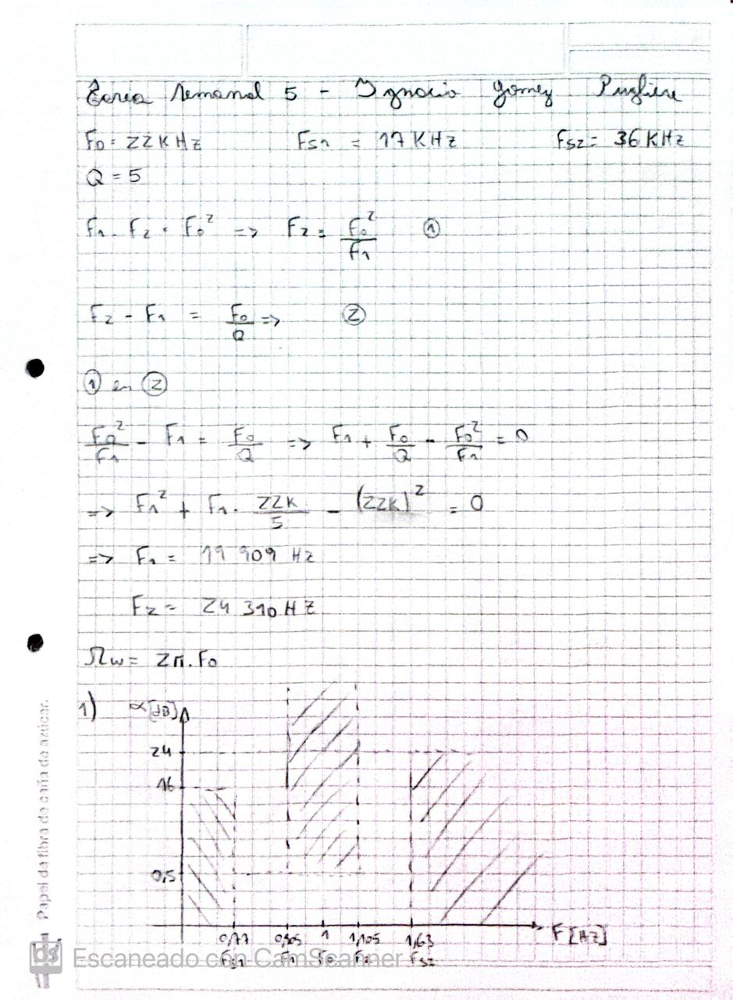
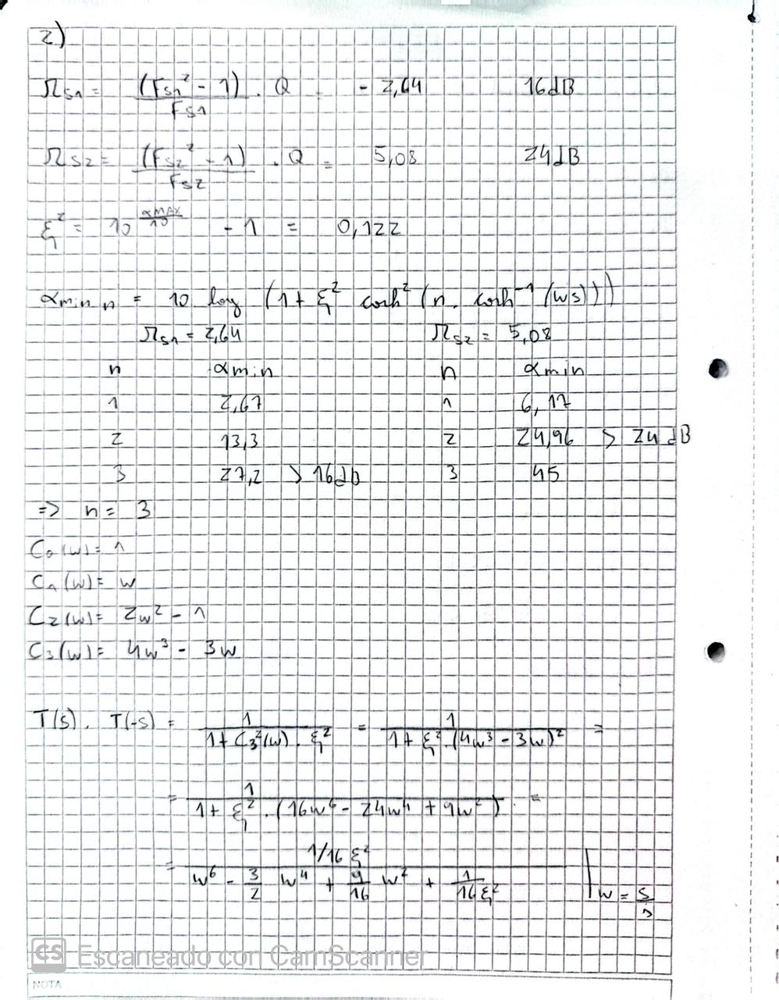
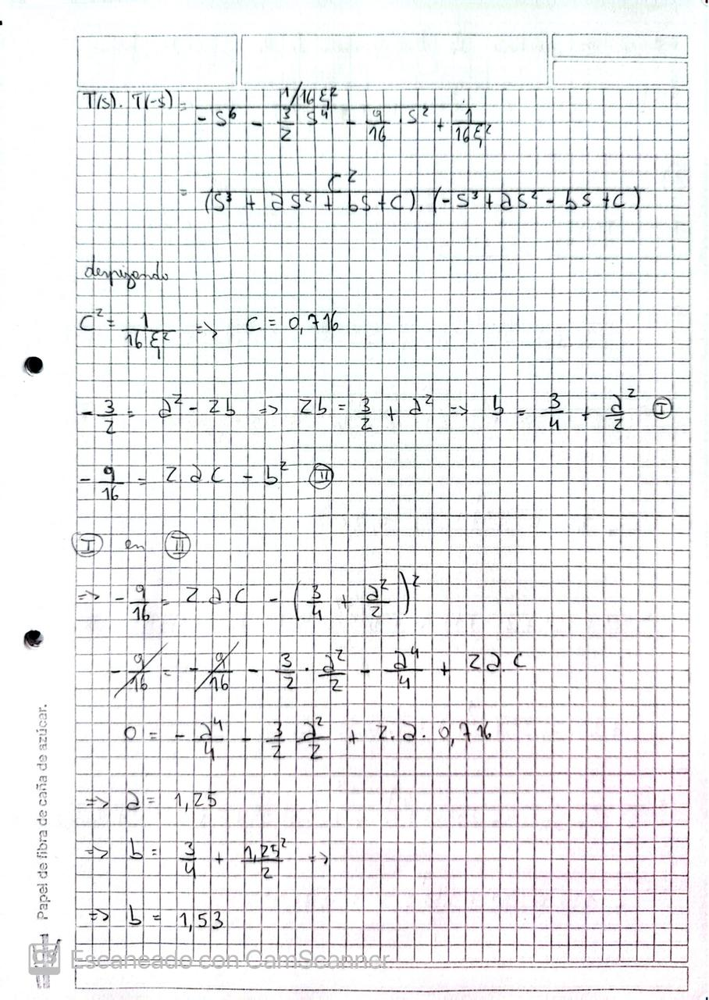
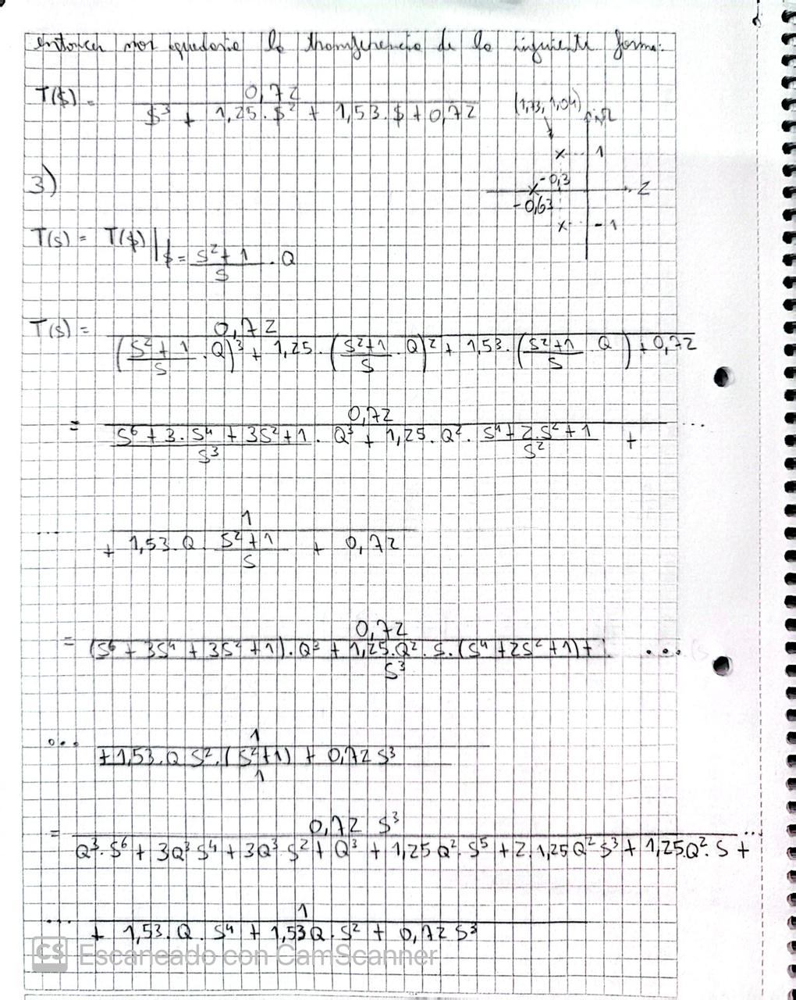
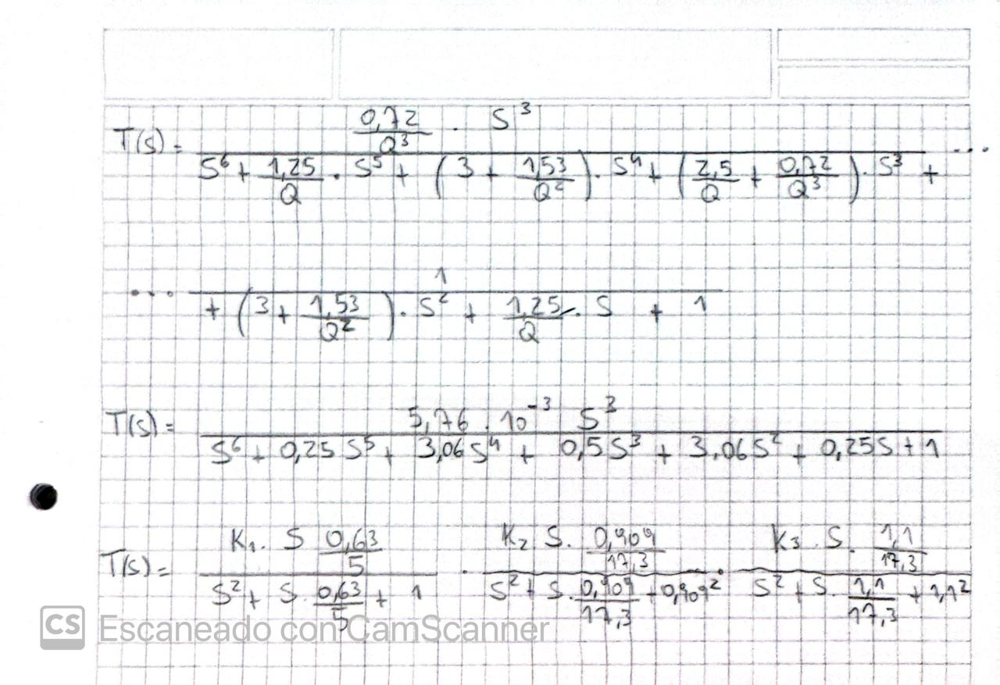

#### Prototipo de tercer orden

<IPython.core.display.Math object>

#### Pasabanda obtenido (coeficientes de los polinomios)

[0.00576 0.      0.      0.     ]
[1.      0.25    3.0612  0.50576 3.0612  0.25    1.     ]


#### Pasabanda visto como cociente de polinomios

<IPython.core.display.Math object>

#### Pasabanda factorizado en secciones bicuadráticas (SOS)

<IPython.core.display.Math object>

#### Pasabanda factorizado en SOS parametrizadas $\omega_0$ y $Q$

<IPython.core.display.Math object>

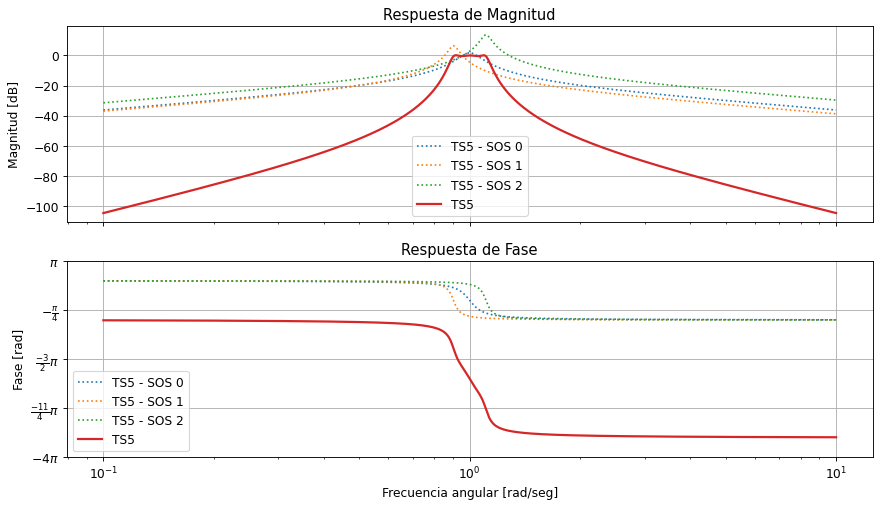

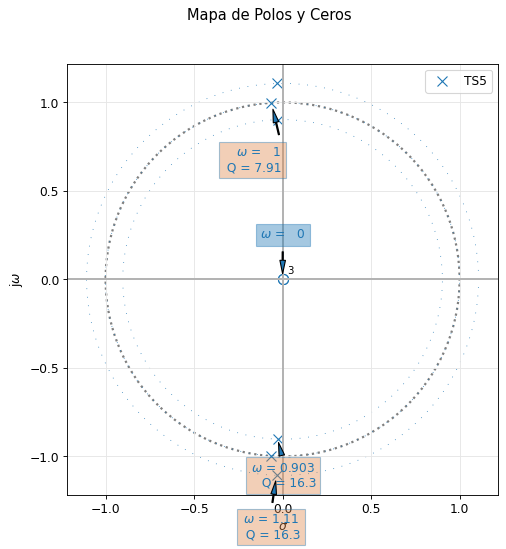

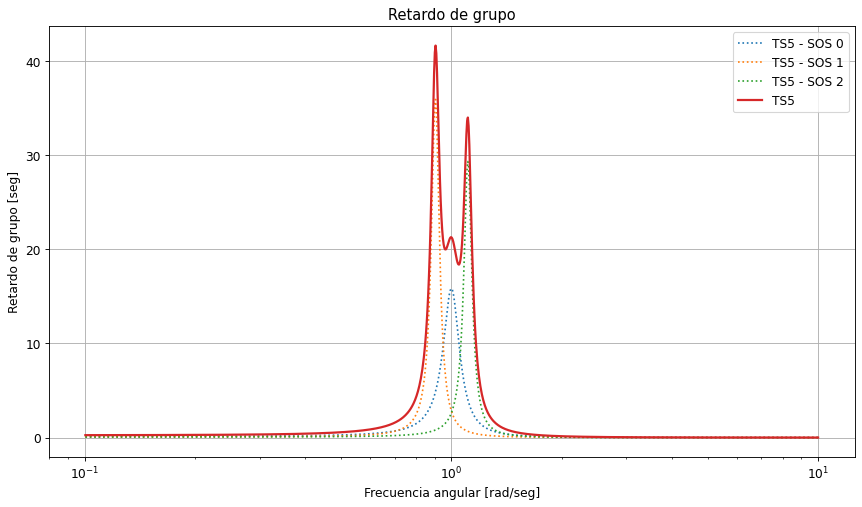

In [2]:
import sympy as sp
from sympy.abc import s
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal as sig
import sys
sys.path.append('/home/ignacio/Escritorio/Facultad/2025/TC2/TC2_Virtual/lib/python3.12/site-packages')

fig_sz_x = 13
fig_sz_y = 7
fig_dpi = 80 # dpi

fig_font_size = 11

mpl.rcParams['figure.figsize'] = (fig_sz_x, fig_sz_y)
mpl.rcParams['figure.dpi'] = fig_dpi
plt.rcParams.update({'font.size':fig_font_size})

import numpy as np
import scipy.signal as sig
from IPython.display import display, Markdown

# Ahora importamos las funciones de PyTC2

from pytc2.sistemas_lineales import analyze_sys, parametrize_sos, pretty_print_lti, pretty_print_bicuad_omegayq, tf2sos_analog, pretty_print_SOS
from pytc2.general import print_latex, print_subtitle, a_equal_b_latex_s

# coeficientes de la transferencia de tercer orden T3
T3_num = np.array([0.72])
T3_den = np.array([1, 1.25, 1.53, 0.72])

# Q de la transformación
Q_bp = 5

# núcleo LP-BP
num_pbanda, den_pbanda = sig.lp2bp(T3_num, T3_den, bw = 1/Q_bp)

print_subtitle('Prototipo de tercer orden')

print_latex(a_equal_b_latex_s('$ T_{lp}(s)', sp.latex( 0.72/(s**3 + s**2 * 1.25 + s * 1.53 + 0.72) )))

print_subtitle('Pasabanda obtenido (coeficientes de los polinomios)')

print(num_pbanda)
print(den_pbanda)

print_subtitle('Pasabanda visto como cociente de polinomios')

# forma un poco más clara
#pretty_print_lti(num_pbanda, den_pbanda)
print_latex(a_equal_b_latex_s('T_{bp}(s)', pretty_print_lti(num_pbanda, den_pbanda, displaystr=False)))

print_subtitle('Pasabanda factorizado en secciones bicuadráticas (SOS)')

sos_pbanda = tf2sos_analog(num_pbanda, den_pbanda)

# la visualizamos de algunas formas, la tradicional
#pretty_print_SOS(sos_pbanda)
print_latex(a_equal_b_latex_s('T_{bp}(s)', pretty_print_SOS(sos_pbanda, displaystr=False)))

print_subtitle('Pasabanda factorizado en SOS parametrizadas $\omega_0$ y $Q$')

#pretty_print_SOS(sos_pbanda, mode='omegayq')
print_latex(a_equal_b_latex_s('T_{bp}(s)', pretty_print_SOS(sos_pbanda, mode='omegayq', displaystr=False)))

T6_bp =  sig.TransferFunction( num_pbanda, den_pbanda )

# el caracter "_" descarta la salida de la función
#_ = analyze_sys(T6_bp, sys_name='pasabanda 6to orden Q={:d}'.format(Q_bp))

from IPython.display import display, Markdown

# el caracter "_" descarta la salida de la función
_ = analyze_sys( sos_pbanda, 'TS5' )